# Q1 (a) — Iris classification experiment

Train a simple model on the Iris dataset and report **accuracy** and **F1-score** (macro).
This notebook is the exploratory version; part (b) turns it into `prepare.py` → `train.py` → `evaluate.py` driven by `params.yaml`.

In [1]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## 1. Load data

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.rename(columns={
    'sepal length (cm)': 'sepal_length', 'sepal width (cm)': 'sepal_width',
    'petal length (cm)': 'petal_length', 'petal width (cm)': 'petal_width'})
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))
df = df.drop(columns='target')
print(df.shape)
print(df['species'].value_counts())
df.head()

(150, 5)
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. Train / test split (stratified)

In [3]:
FEATURES = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
PARAMS = {'test_size': 0.2, 'random_state': 42, 'n_estimators': 10, 'max_depth': 2}

train, test = train_test_split(df, test_size=PARAMS['test_size'],
                               random_state=PARAMS['random_state'], stratify=df['species'])
X_train, y_train = train[FEATURES], train['species']
X_test, y_test = test[FEATURES], test['species']
print(f'train={len(train)}  test={len(test)}')

train=120  test=30


## 3. Train models and report accuracy & F1

In [4]:
models = {
    'RandomForest (depth=2, n=10)': RandomForestClassifier(n_estimators=PARAMS['n_estimators'], max_depth=PARAMS['max_depth'], random_state=42),
    'LogisticRegression (C=1.0)': LogisticRegression(C=1.0, max_iter=200, random_state=42),
}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({'model': name,
                 'accuracy': round(accuracy_score(y_test, pred), 4),
                 'f1_macro': round(f1_score(y_test, pred, average='macro'), 4)})
results = pd.DataFrame(rows)
print(results.to_string(index=False))

                       model  accuracy  f1_macro
RandomForest (depth=2, n=10)    0.9333    0.9333
  LogisticRegression (C=1.0)    0.9667    0.9666


## 4. Detailed report for the baseline model (Random Forest)
This is the model carried into the DVC pipeline.

In [5]:
rf = models['RandomForest (depth=2, n=10)']
pred = rf.predict(X_test)
print(f"Accuracy : {accuracy_score(y_test, pred):.4f}")
print(f"F1 (macro): {f1_score(y_test, pred, average='macro'):.4f}\n")
print(classification_report(y_test, pred))

Accuracy : 0.9333
F1 (macro): 0.9333

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



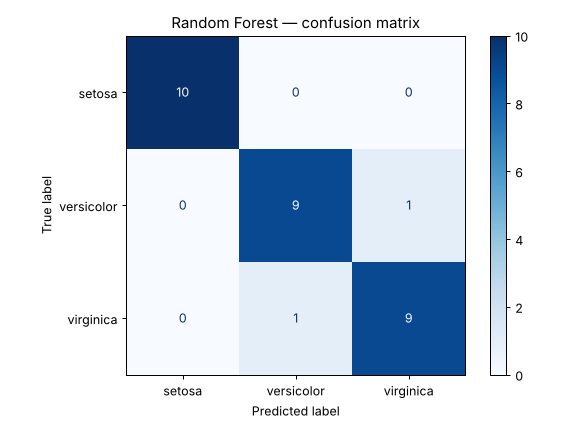

In [6]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Blues')
plt.title('Random Forest — confusion matrix')
plt.tight_layout()
plt.show()

## 5. Conclusion
- Random Forest (`max_depth=2`, `n_estimators=10`): **accuracy 0.9333, F1 0.9333** on the 30-sample test set.
- Setosa is separated perfectly; the few errors are between *versicolor* and *virginica*.
- Next step (b): move these hard-coded values into `params.yaml` and split the notebook into reproducible scripts.